# 02 — Experiments & Evaluation
Compare classical TF-IDF models, BiLSTM curves, confusion matrices, and error analysis.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src.evaluate import predict_post
from src.utils import RESULTS_DIR

pd.read_csv(RESULTS_DIR / 'model_comparison.csv')

,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,LinearSVM_Tuned,0.9636,0.9652,0.9650,0.9649,0.9635,0.9636,0.9634
1,LinearSVM,0.9636,0.9652,0.9650,0.9649,0.9635,0.9636,0.9634
2,LogisticRegression,0.9592,0.9609,0.9604,0.9605,0.9591,0.9592,0.9591
3,BiLSTM,0.9569,0.9604,0.9576,0.9589,0.9569,0.9569,0.9567
4,LinearSVM_WordOnly,0.9555,0.9582,0.9569,0.9575,0.9554,0.9555,0.9553
5,MultinomialNB,0.8289,0.8742,0.8236,0.8315,0.8664,0.8289,0.8303


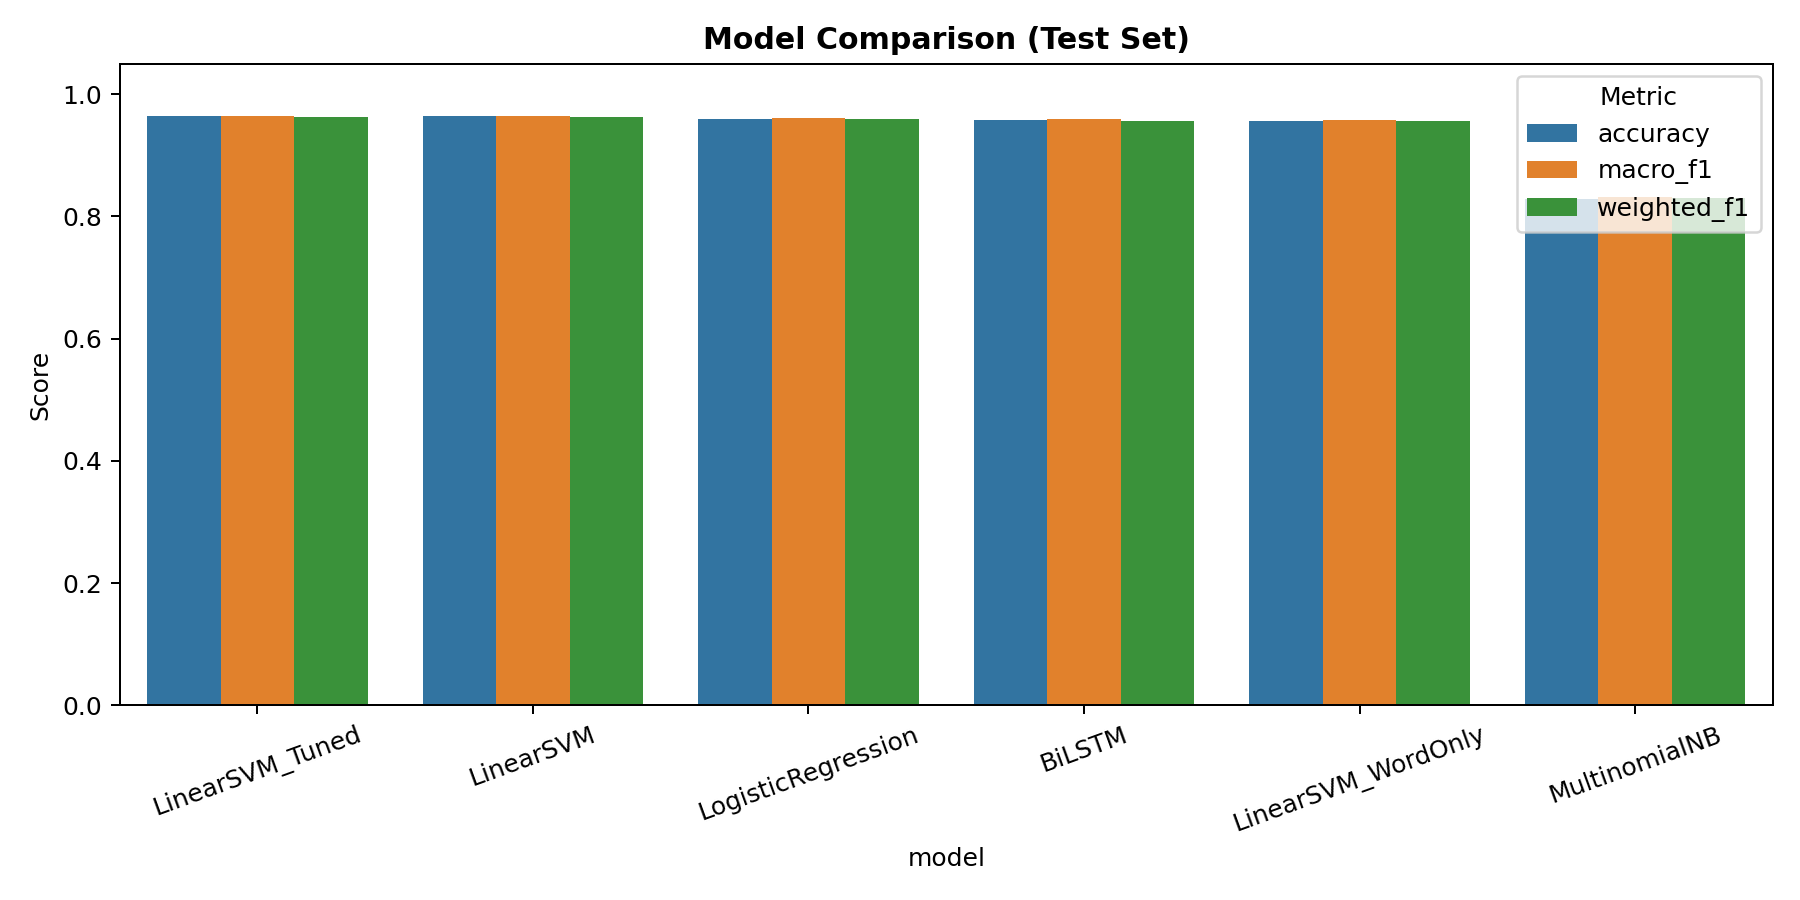

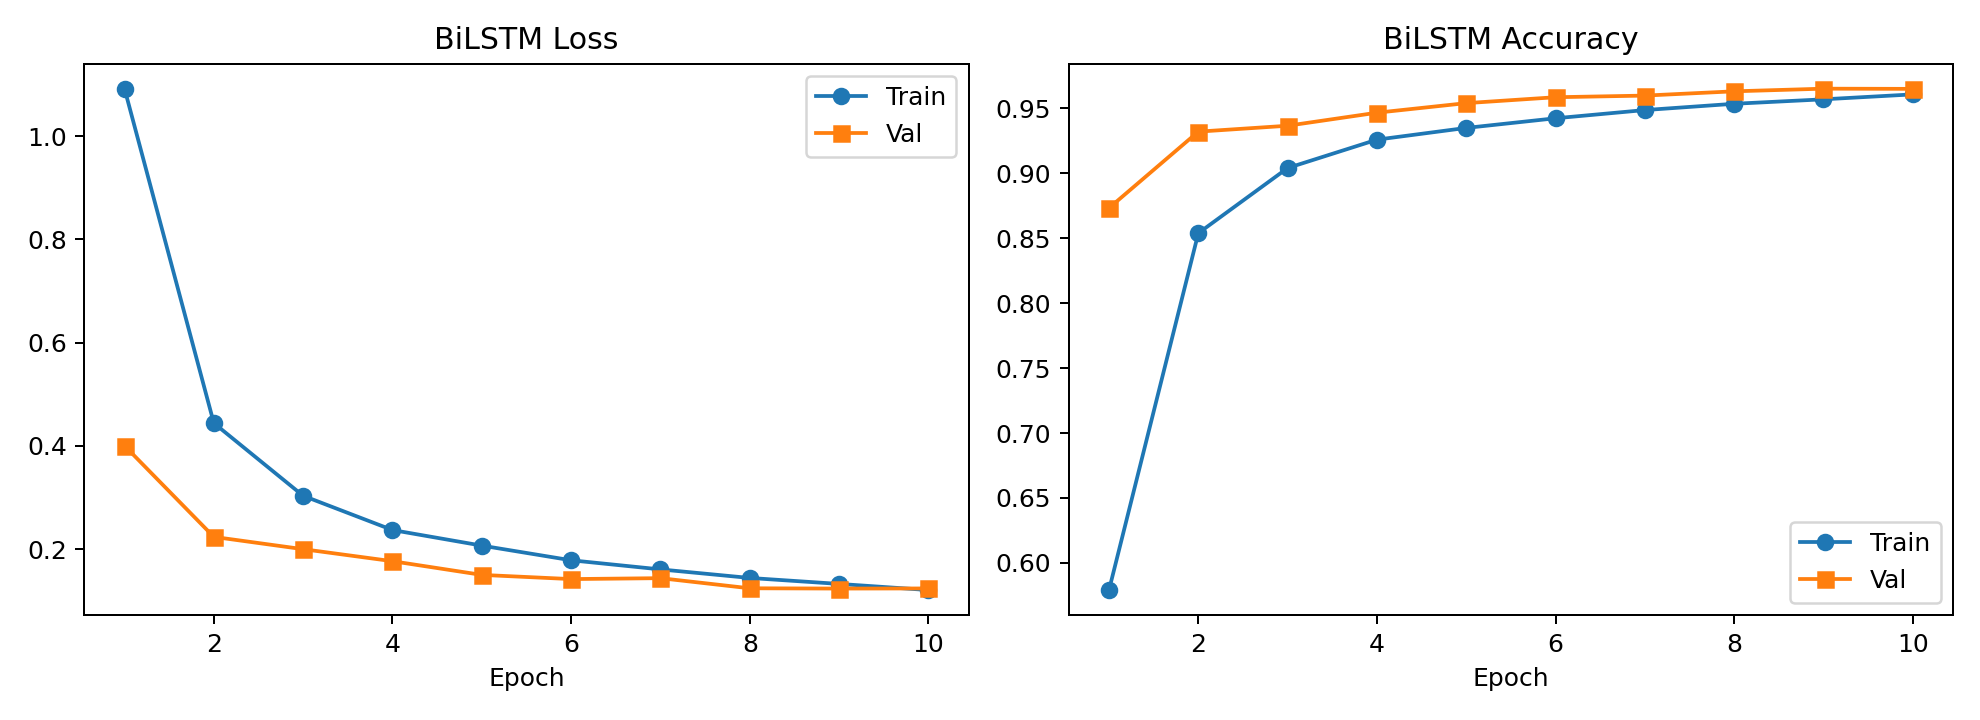

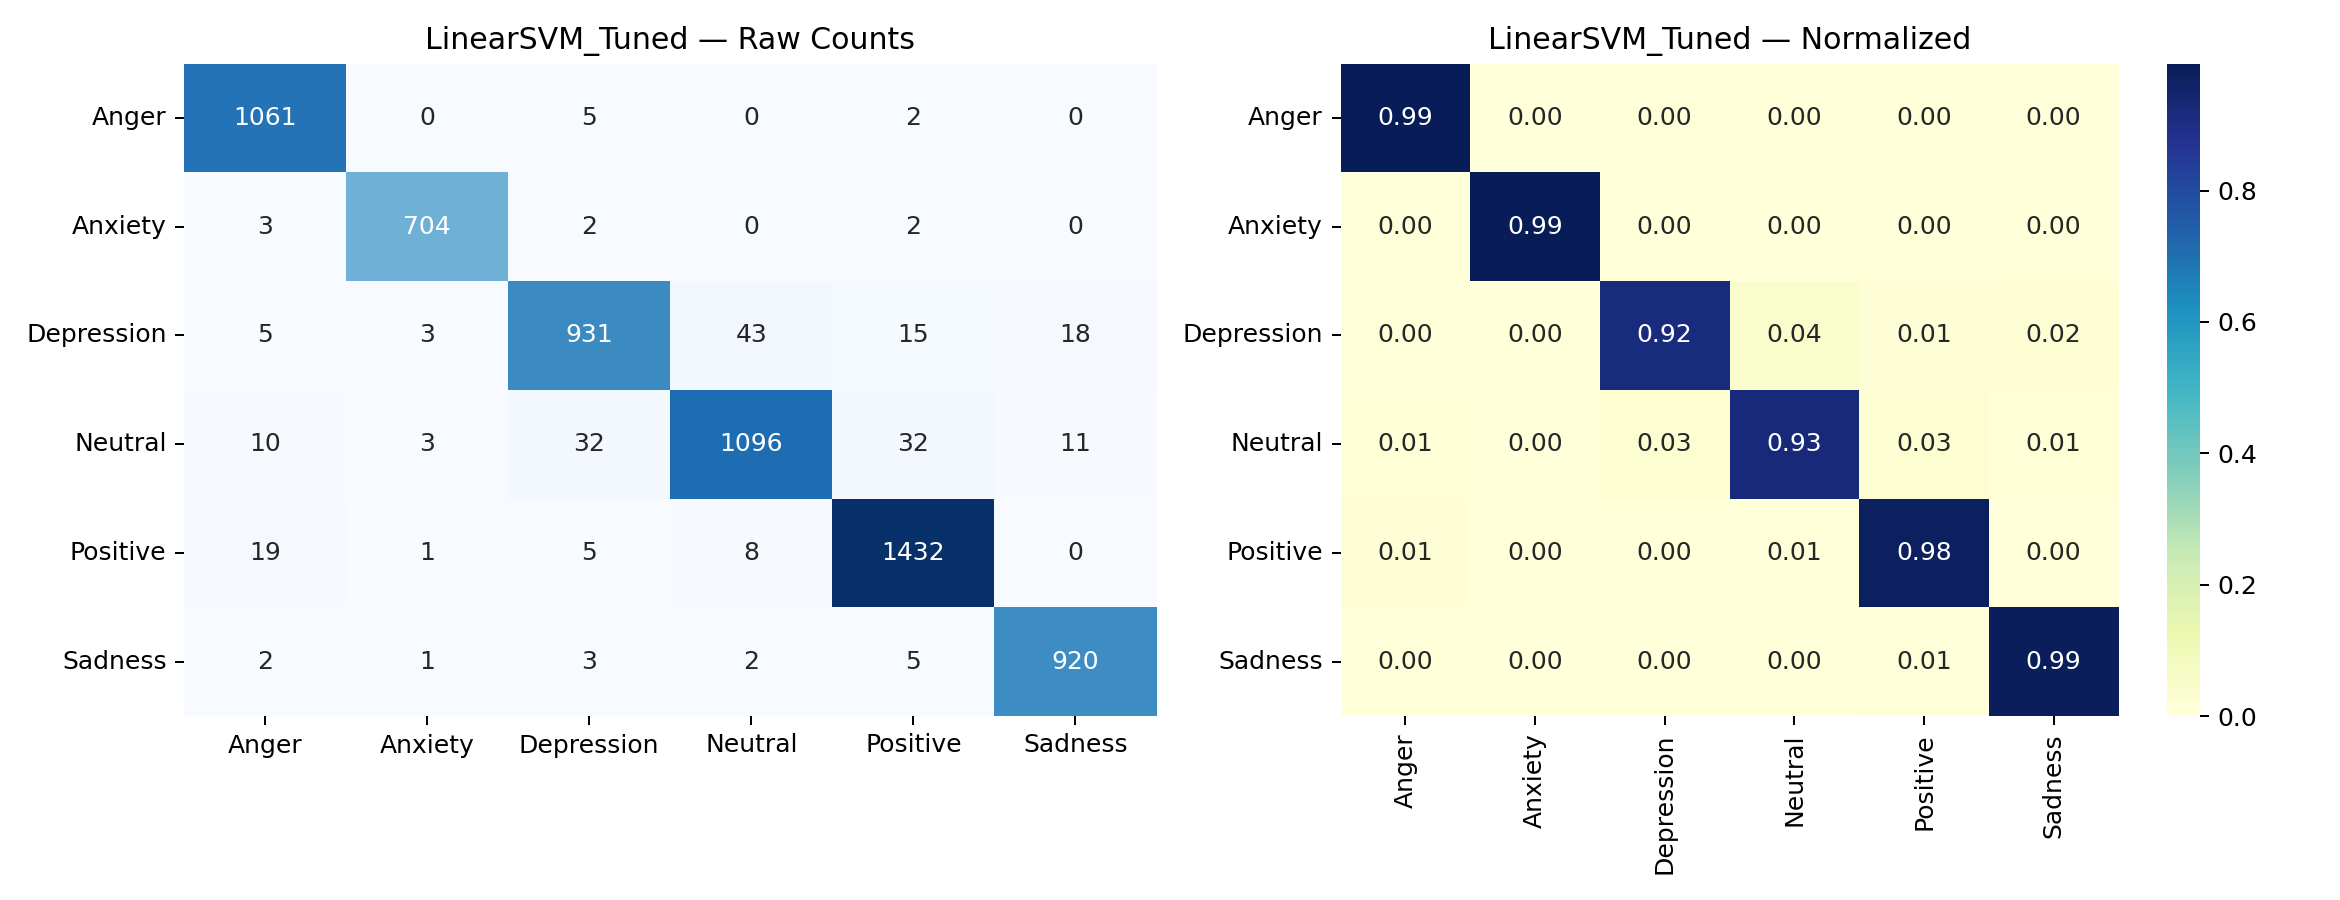

In [2]:
for img in ['model_comparison.png', 'bilstm_training_curves.png', 'best_model_confusion_matrix.png']:
    display(Image(filename=str(RESULTS_DIR / img)))

In [3]:
pd.read_csv(RESULTS_DIR / 'error_analysis.csv')

,true_label,predicted_label,confidence,raw_text
0,Depression,Sadness,0.8643,I can feel it on my heart. I do not even have ...
1,Neutral,Sadness,0.8537,is sad that the march break is over
2,Positive,Anger,0.8481,i feel angry im happy
3,Neutral,Depression,0.8396,Once I committed mentally to therapy and knew ...
4,Depression,Neutral,0.7913,"CAN you? did not sink so. You can ban me once,..."
5,Sadness,Anger,0.7744,i feel hated i feel angry i feel very sad i fe...
6,Neutral,Anxiety,0.7190,Wish to get a surprise in May .Want to be able...
7,Depression,Anger,0.6887,Want to kill myself because of it. God I hate ...
8,Anger,Depression,0.6831,im feeling all preasured and all from fueds be...
9,Anger,Positive,0.6617,i feel defeated unhappy and whatever the oppos...


In [4]:
posts = [
    'Nothing brings me joy anymore, I feel empty every day.',
    'This makes me so angry and furious right now!!',
    'I am feeling worried and scared about my exam tomorrow!',
]
pd.DataFrame([predict_post(p, model_choice='LogisticRegression') for p in posts])

,raw_text,cleaned_text,model_used,predicted_label,confidence
0,"Nothing brings me joy anymore, I feel empty ev...",nothing brings joy anymore feel empty every day,LogisticRegression,Depression,0.5281
1,This makes me so angry and furious right now!!,make angry furious right,LogisticRegression,Anger,0.9760
2,I am feeling worried and scared about my exam ...,feeling worried scared exam tomorrow,LogisticRegression,Anxiety,0.4709
